[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/grabuffo/brain-modeling-course/blob/main/notebooks/D2_C4_NB07_criticality_chaos.ipynb)

# Day 2 · Chapter 4 · Notebook 07 — Criticality and chaos: small causes, big effects

Two ways in which a tiny cause has a huge effect: **criticality**, where one spike can start a cascade of any size
(Part A), and **chaos**, where a tiny difference in the start changes the whole future (Part B).

Criticality is a bifurcation of a whole network: below a critical point activity dies out, above it activity takes
over. The knob here is the **branching ratio** $\sigma$, and the critical point is $\sigma=1$. (NB08 then looks at the
bifurcations inside single models.)

In [1]:
# @title Setup (run once)
# On Google Colab this downloads the course code; on your laptop it does nothing.
import sys, os
if "google.colab" in sys.modules:
    if not os.path.exists("/content/brain-modeling-course"):          # first run: download the course code
        !git clone -q https://github.com/grabuffo/brain-modeling-course.git /content/brain-modeling-course
        !pip -q install numba ipywidgets
    %cd /content/brain-modeling-course/notebooks
sys.path.insert(0, os.path.abspath(".."))   # so that `import src` works

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from src import plotting
from src.plotting import slider
plotting.setup()
from matplotlib.colors import LinearSegmentedColormap
REG = {"sub": "0.35", "crit": "C0", "super": "C3"}   # colours: subcritical grey, critical blue, supercritical red

# Part A · Criticality

## 1. One spike, and its children

Each spike makes, on average, $\sigma$ new spikes in the next step (the **branching ratio**). We start 10 of 5000
neurons and follow the activity.

<details><summary>The model (for the curious)</summary>

$N = 5000$ neurons, all connected. Each spike has a random number of "children" (Poisson, mean $\sigma$), each a
random neuron that fires in the next step. In a real network $\sigma = p\,(N-1)$, with $p$ the probability that a
spike makes a given neuron fire: only $p\approx1/N$ gives $\sigma\approx1$ (Shew & Plenz 2013).
</details>

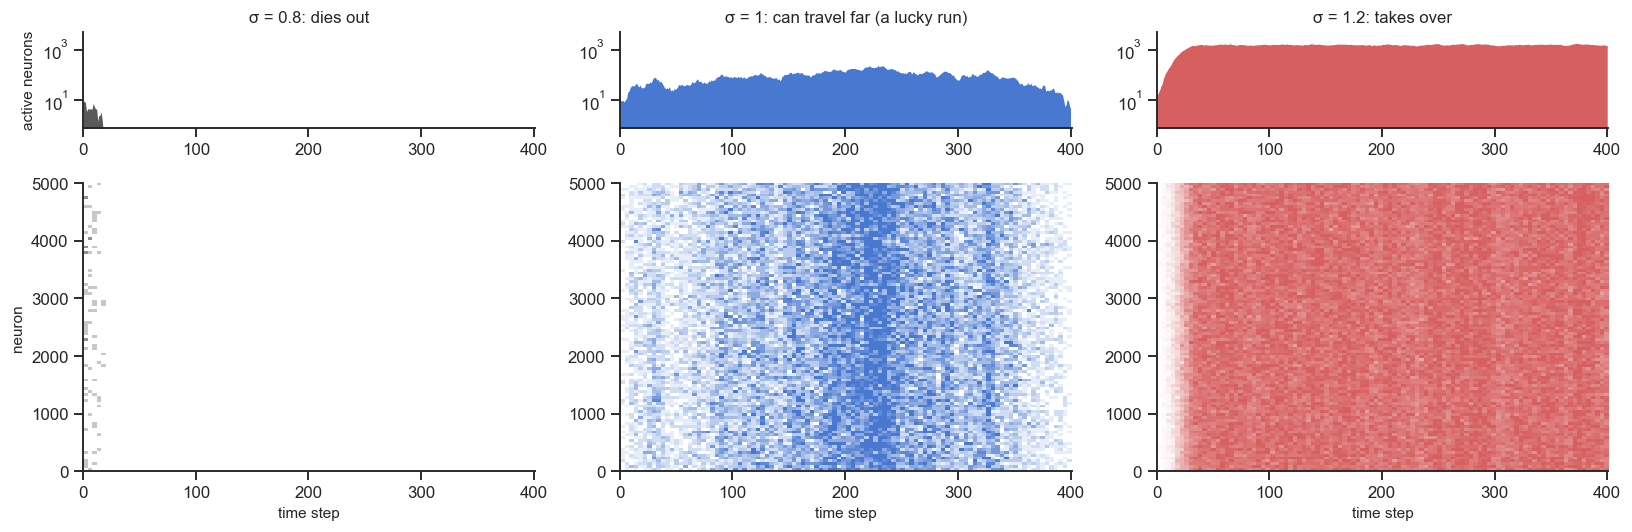

In [2]:
# @title Branching network: one run below (σ = 0.8), at (σ = 1) and above (σ = 1.2) the critical point
N_NET = 5000
def run_net(sigma, T=400, A0=10, seed=0):
    # raster (neurons x time steps), started by A0 active neurons
    rng = np.random.default_rng(seed)
    s = np.zeros(N_NET, bool); s[rng.choice(N_NET, A0, replace=False)] = True; out = [s]
    for t in range(T):
        children = rng.integers(N_NET, size=rng.poisson(sigma * s.sum()))   # each spike has on average sigma children
        s = np.zeros(N_NET, bool); s[children] = True; out.append(s)
    return np.array(out).T

def binned(R, bn=50, bt=4):                                             # spikes per block of 50 neurons x 4 steps
    n, T = R.shape; T = T // bt * bt
    return R[:, :T].reshape(n // bn, bn, T // bt, bt).sum(axis=(1, 3))

def example(sigma, want):                                               # an example run of each kind (critical: one that survived)
    for seed in range(3000):
        R = run_net(sigma, seed=seed); a = R.sum(0); last = np.nonzero(a)[0].max()
        if (want == "sub" and 15 <= last <= 40) or (want == "crit" and last == R.shape[1] - 1 and a.max() < 300) or (want == "super" and a[-1] > 0):
            return R
    return R

def raster_panel(ax_top, ax_bot, R, colour, title):
    T = R.shape[1]
    ax_top.fill_between(np.arange(T), R.sum(0) + 0.5, 0.5, color=colour, lw=0)
    ax_top.set(yscale="log", ylim=(0.8, N_NET), xlim=(0, T), title=title)
    cm = LinearSegmentedColormap.from_list("w", ["white", colour])
    B = binned(R); vmax = max(3, np.percentile(B[B > 0], 90)) if B.any() else 3   # colour scale adapted to the run
    ax_bot.imshow(B, aspect="auto", origin="lower", cmap=cm, vmin=0, vmax=vmax, extent=(0, T, 0, N_NET), interpolation="nearest")
    ax_bot.set(xlabel="time step")

CASES = [(0.8, "sub", "σ = 0.8: dies out"), (1.0, "crit", "σ = 1: can travel far (a lucky run)"), (1.2, "super", "σ = 1.2: takes over")]
fig, ax = plt.subplots(2, 3, figsize=(15, 5), gridspec_kw=dict(height_ratios=[1, 3]))
for j, (sig, key, name) in enumerate(CASES):
    raster_panel(ax[0, j], ax[1, j], example(sig, key), REG[key], name)
ax[0, 0].set_ylabel("active neurons"); ax[1, 0].set_ylabel("neuron")
plt.tight_layout(); plt.show()

Bottom: the 5000 neurons over time (darker = more spikes); top: number of active neurons (log scale).
**Grey:** the activity fades. **Red:** it invades the network and stays, like a seizure. **Blue:** it wanders for
hundreds of steps without dying or taking over. This blue run was picked among those that survived: at $\sigma=1$
most runs die early, a few last very long (the survival curve in the Explore panel below).

### Explore: the branching ratio
* Move $\sigma$ slowly through 1. One run can die by chance even above 1; the right panel shows how many of 2000
  runs survive.

In [3]:
# @title Explore: one run and the survival of 2000 runs, for any branching ratio
def run_counts(sigma, T, n_runs, A0=10, h=0.0, seed=0):
    # same network, only the number of active neurons, for many runs at once (h = outside input per neuron per step)
    rng = np.random.default_rng(seed); A = np.full(np.broadcast(n_runs, sigma, h).shape, A0); out = [A]
    for t in range(T):
        A = rng.binomial(N_NET, 1 - np.exp(-sigma * A / N_NET - h)); out.append(A)
    return np.array(out)

SEED = next(k for k in range(3000) if run_net(1.0, seed=k)[:, -1].any())   # a run that survives at σ = 1, reused for every σ

@interact(sigma=slider(1.0, 0.5, 1.5, 0.05, "branching ratio σ"))
def explore_sigma(sigma):
    key = "sub" if sigma < 0.98 else "super" if sigma > 1.02 else "crit"
    fig, ax = plt.subplots(2, 2, figsize=(13, 4.2), gridspec_kw=dict(width_ratios=[2, 1], height_ratios=[1, 3]))
    raster_panel(ax[0, 0], ax[1, 0], run_net(sigma, seed=SEED), REG[key], f"one run, σ = {sigma:.2f}")
    ax[0, 0].set_ylabel("active neurons"); ax[1, 0].set_ylabel("neuron")
    ax[0, 1].axis("off"); A = run_counts(sigma, 400, np.zeros(2000))
    ax[1, 1].plot((A > 0).mean(1), c=REG[key]); ax[1, 1].set(yscale="log", ylim=(1e-3, 1.1), xlabel="time step", ylabel="fraction of runs still active", title="2000 runs")
    plt.tight_layout(); plt.show()

## 2. Avalanches: no typical size

**What is an avalanche?** Cut the recording into time steps. An **avalanche** is a stretch of consecutive steps with
at least one spike, from one silent step to the next. Its **size** is the total number of spikes inside it.
Below: 50 neurons at $\sigma=1$; after each silence one neuron fires and may start the next avalanche.

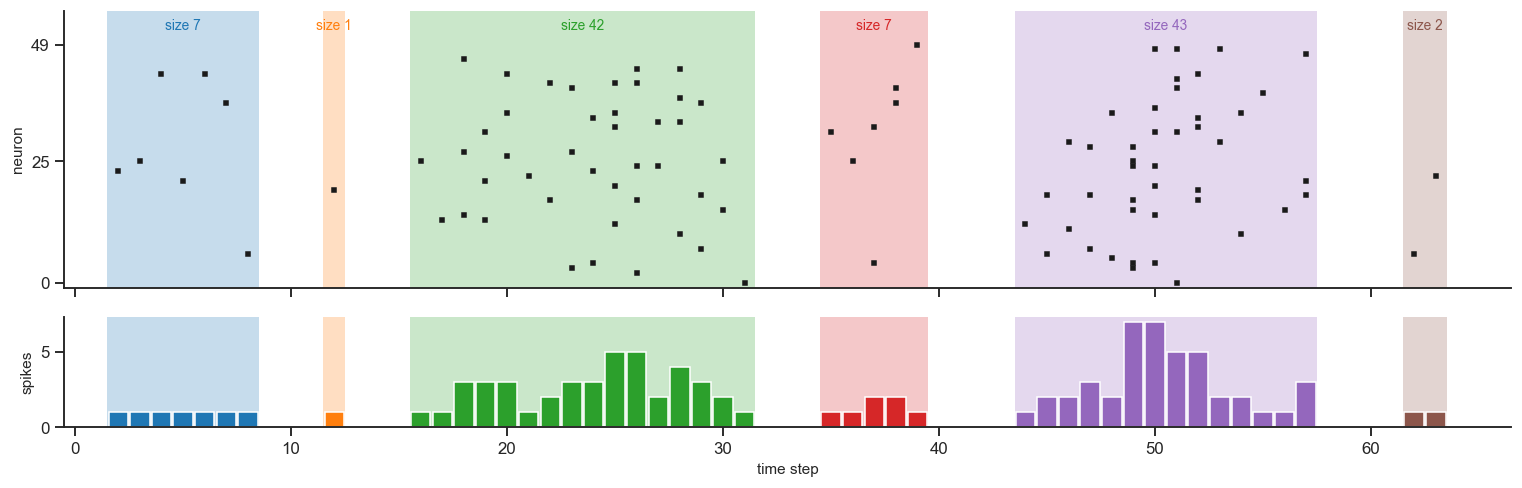

In [4]:
# @title What is an avalanche: a binary raster of a small critical network, each avalanche shaded in its own colour
def small_avalanche(rng, n=50, sigma=1.0, max_len=40):
    s = np.zeros(n, bool); s[rng.integers(n)] = True; out = [s]            # one spike starts it
    while out[-1].any() and len(out) <= max_len:
        s = np.zeros(n, bool); s[rng.integers(n, size=rng.poisson(sigma * out[-1].sum()))] = True; out.append(s)
    return np.array(out[:-1]).T if not out[-1].any() else None               # None: too long for the example

def avalanche_sequence(seed, T=110):
    rng = np.random.default_rng(seed); cols, spans = [np.zeros((50, 2), bool)], []
    while sum(c.shape[1] for c in cols) < T - 45:
        a = small_avalanche(rng)
        if a is None: continue
        t0 = sum(c.shape[1] for c in cols); spans.append((t0, t0 + a.shape[1], int(a.sum())))
        cols += [a, np.zeros((50, rng.integers(2, 5)), bool)]               # silent steps between avalanches
    return np.hstack(cols), spans

seed = next(k for k in range(500) if len(avalanche_sequence(k)[1]) >= 6 and max(s for *_, s in avalanche_sequence(k)[1]) >= 30)
RASTER, SPANS = avalanche_sequence(seed)
fig, ax = plt.subplots(2, 1, figsize=(14, 4.6), sharex=True, gridspec_kw=dict(height_ratios=[3, 1.2]))
for k, (t0, t1, size) in enumerate(SPANS):
    c = plt.cm.tab10(k % 10)
    for a in ax: a.axvspan(t0 - 0.5, t1 - 0.5, color=c, alpha=0.25, lw=0)
    ax[0].text((t0 + t1 - 1) / 2, 51.5, f"size {size}", ha="center", va="bottom", fontsize=9, color=c)
    ax[1].bar(np.arange(t0, t1), RASTER[:, t0:t1].sum(0), width=0.9, color=c)
n_i, t_i = np.nonzero(RASTER)
ax[0].plot(t_i, n_i, "ks", ms=3)
ax[0].set(ylabel="neuron", ylim=(-1, 56), yticks=[0, 25, 49])
ax[1].set(xlabel="time step", ylabel="spikes", xlim=(-0.5, RASTER.shape[1] - 0.5)); ax[1].yaxis.get_major_locator().set_params(integer=True)
plt.tight_layout(); plt.show()

Top: each black square is a spike (neuron × time step), and each coloured band is one avalanche. Bottom: spikes per
time step. The avalanches start the same way, with one spike, yet their sizes differ by more than ten times.

Now we start 100 000 avalanches from **one** spike in the big network and count the size of each. At $\sigma=1$
there is no typical size: on log–log axes the distribution is a straight line, a **power law**. This is the
signature looked for in real brains (Beggs & Plenz 2003).

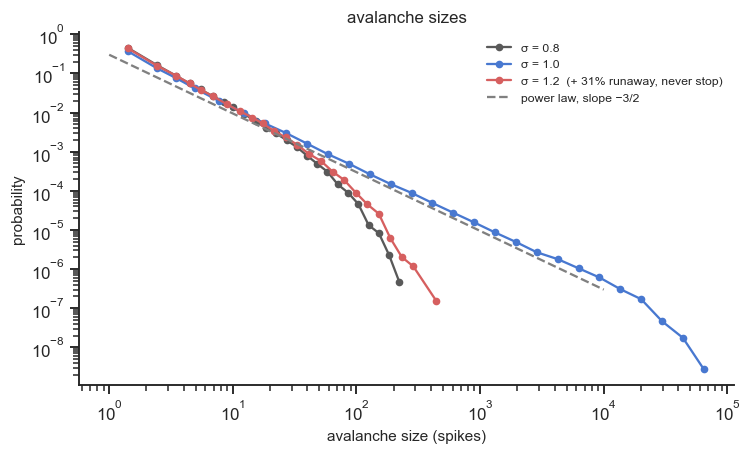

In [5]:
# @title Avalanche sizes from 100 000 cascades started by one spike, below, at and above σ = 1
def avalanche_sizes(sigma, n=100_000, T=2000, seed=1):
    rng = np.random.default_rng(seed); A = np.ones(n, int); size = A.copy()
    for t in range(T):
        live = A > 0                                                     # only active cascades need updating
        A[live] = rng.binomial(N_NET, 1 - np.exp(-sigma * A[live] / N_NET)); size += A
    ended = A == 0                                                       # cascades that stopped within T steps
    return size[ended], 1 - ended.mean()

def log_hist(x, n_bins=30):
    edges = np.unique(np.logspace(0, np.log10(x.max() + 1), n_bins).astype(int)); h, _ = np.histogram(x, edges)
    c = np.sqrt(edges[:-1] * edges[1:]); ok = h > 0
    return c[ok], (h / np.diff(edges) / len(x))[ok]

fig, ax = plt.subplots(figsize=(7, 4.3))
for sig, key in [(0.8, "sub"), (1.0, "crit"), (1.2, "super")]:
    sizes, runaway = avalanche_sizes(sig)
    lab = f"σ = {sig}" + (f"  (+ {100 * runaway:.0f}% runaway, never stop)" if runaway > 0.01 else "")
    xs, P = log_hist(sizes); ax.plot(xs, P, "o-", ms=4, c=REG[key], label=lab)
xx = np.logspace(0, 4, 10); ax.plot(xx, 0.3 * xx ** -1.5, "--", c="0.5", label="power law, slope −3/2")
ax.set(xscale="log", yscale="log", xlabel="avalanche size (spikes)", ylabel="probability", title="avalanche sizes")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

Grey: only small avalanches. Blue: a straight line over four decades. Red: small avalanches, plus runaway
cascades that never stop (not in the histogram).

<details><summary>Power laws, scale invariance, universality (for the curious)</summary>

$P(s)\propto s^{-3/2}$: an avalanche 10 times bigger is $10^{3/2}\approx32$ times rarer, whatever size you start from,
so every zoom of the curve looks the same (**scale invariance**); an exponential decay instead has a typical size.
The exponent does not depend on the details: slope about $-3/2$ is found in this model, in cortical slices and in
awake monkeys (one **universality class**; Petermann et al. 2009). A power law alone does not prove criticality,
which is why functional tests (next section) matter.
</details>

## 3. Why sit at σ = 1: the widest range of inputs

Drive the network with outside input, from very weak to very strong, and measure the response (fraction of neurons
active). The **dynamic range** is the span of input intensities that the response can tell apart.

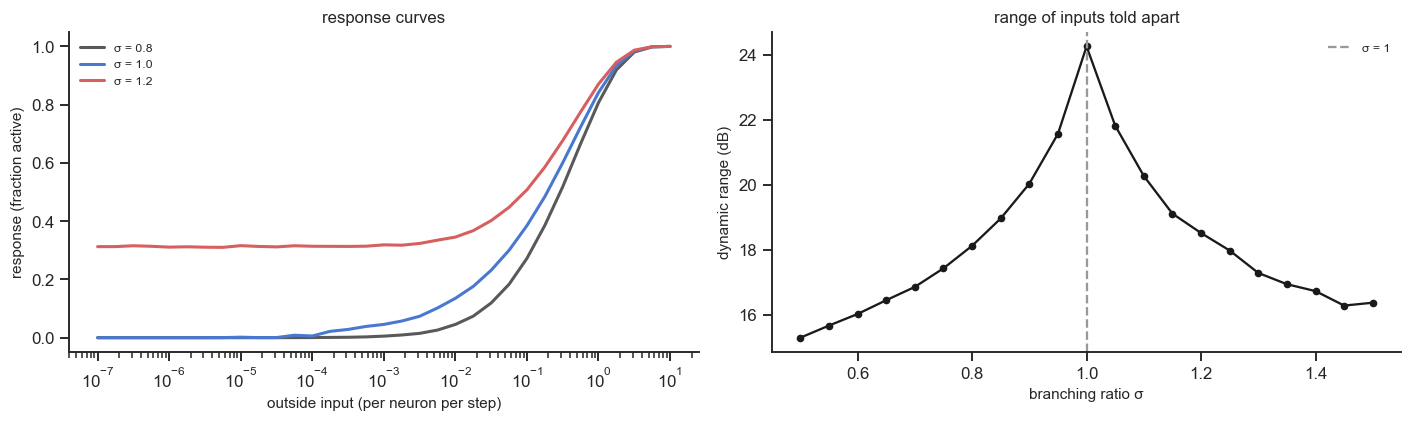

In [6]:
# @title Response to outside input and dynamic range, for many branching ratios (a few seconds)
hs = np.logspace(-7, 1, 33)                                              # outside input per neuron per step
sig_scan = np.round(np.arange(0.5, 1.501, 0.05), 2)
A0 = np.where(sig_scan[:, None] > 1, N_NET // 2, 0) * np.ones((1, hs.size), int)   # supercritical: start in its own active state
A = run_counts(sig_scan[:, None], 600, np.zeros((sig_scan.size, hs.size)), A0=A0, h=hs[None, :], seed=2)
F = A[200:].mean(0) / N_NET                                              # mean response after a transient

def dynamic_range(F, hs):                                                # dB of input between 10% and 90% of the response
    lo, hi = F[0] + 0.1 * (F[-1] - F[0]), F[0] + 0.9 * (F[-1] - F[0])
    return 10 * np.log10(10 ** np.interp(hi, F, np.log10(hs)) / 10 ** np.interp(lo, F, np.log10(hs)))
DR = np.array([dynamic_range(f, hs) for f in F])

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for sig, key in [(0.8, "sub"), (1.0, "crit"), (1.2, "super")]:
    i = np.argmin(abs(sig_scan - sig)); ax[0].semilogx(hs, F[i], c=REG[key], lw=2, label=f"σ = {sig}")
ax[0].set(xlabel="outside input (per neuron per step)", ylabel="response (fraction active)", title="response curves"); ax[0].legend(fontsize=8)
ax[1].plot(sig_scan, DR, "ko-", ms=4); ax[1].axvline(1, c="0.6", ls="--", label="σ = 1")
ax[1].set(xlabel="branching ratio σ", ylabel="dynamic range (dB)", title="range of inputs told apart"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

Left: the subcritical network (grey) ignores weak inputs; the supercritical one (red) is busy with its own activity
and barely notices them; the critical one (blue) responds to inputs about a hundred times weaker. Right: the dynamic
range peaks at $\sigma=1$: at the balance point the network is most **sensitive**, like any system near a bifurcation
(slides, NB08).

<details><summary>More benefits, and the evidence in real brains (for the curious)</summary>

Dynamic range = 10·log₁₀ of the ratio between the inputs giving 10% and 90% of the response change (Kinouchi &
Copelli 2006). The **information transmitted** between sites and the **repertoire** of distinct patterns also peak
near $\sigma=1$. In cortex, dynamic range and information peak when drugs bring the excitation–inhibition balance
to the point where avalanches are power laws (Shew et al. 2009, 2011; Shew & Plenz 2013).
</details>

# Part B · Chaos

## 4. A tiny difference, a different future

In 1961 Edward Lorenz simulated a toy model of the weather: a layer of air heated from below, which starts to roll
(convection). It has only three variables: $x$ is the speed of the roll, $y$ and $z$ are temperature differences
(between rising and sinking air, and from bottom to top). The heating is the parameter $\rho$:

$$
\begin{aligned}
\frac{dx}{dt} &= 10\,(y - x)\\[2pt]
\frac{dy}{dt} &= x\,(\rho - z) - y\\[2pt]
\frac{dz}{dt} &= x\,y - \tfrac{8}{3}\,z
\end{aligned}
$$

There is no noise and nothing random. Lorenz restarted a simulation from a printout with 3 decimals instead of 6, and
got a different "weather". Here we do the same, and we also follow two runs that start $10^{-8}$ apart.

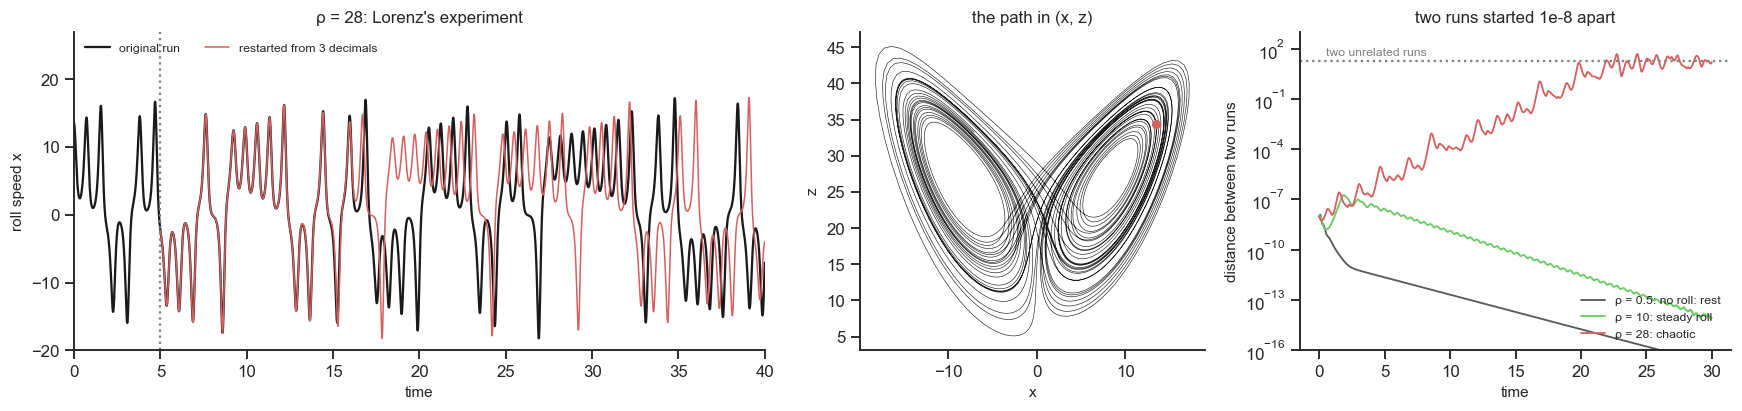

In [7]:
# @title Lorenz system: restart from 3 decimals (left), the attractor (middle), growth of a 1e-8 difference (right)
def lorenz(xyz0, rho, T=40.0, dt=0.01):
    # the three equations above, integrated with Runge-Kutta 4 (accurate); xyz0 can hold several starts
    def speed(v):
        x, y, z = v[..., 0], v[..., 1], v[..., 2]
        return np.stack([10 * (y - x), x * (rho - z) - y, x * y - 8 / 3 * z], -1)
    n = int(round(T / dt)); v = np.asarray(xyz0, float); out = np.empty((n + 1,) + v.shape); out[0] = v
    for i in range(n):
        k1 = speed(v); k2 = speed(v + dt / 2 * k1); k3 = speed(v + dt / 2 * k2); k4 = speed(v + dt * k3)
        out[i + 1] = v = v + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return np.arange(n + 1) * dt, out
dist = lambda a, b: np.linalg.norm(a - b, axis=-1)                        # distance between two runs

START = lorenz([1.0, 1.0, 1.0], 28, T=20)[1][-1]                         # a point on the attractor
NUDGE = np.array([1.0, 0, 0])
CH = {0.5: ("no roll: rest", "0.35"), 10: ("steady roll", "C2"), 28: ("chaotic", "C3")}
t, run = lorenz(START, 28)
far = dist(run[:2000], run[2000:4000]).mean()                            # typical distance of two unrelated moments

t_print = 5
printed = np.round(run[int(t_print / 0.01)], 3)                          # the "printout"
t2, run2 = lorenz(printed, 28, T=t[-1] - t_print)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.9), gridspec_kw=dict(width_ratios=[1.6, 0.8, 1]))
ax[0].plot(t, run[:, 0], "k", lw=1.5, label="original run"); ax[0].plot(t_print + t2, run2[:, 0], "C3", lw=1, label="restarted from 3 decimals")
ax[0].axvline(t_print, c="gray", ls=":"); ax[0].set(xlabel="time", ylabel="roll speed x", xlim=(0, t[-1]), ylim=(-20, 27), title="ρ = 28: Lorenz's experiment")
ax[0].legend(loc="upper left", fontsize=8, ncol=2)
ax[1].plot(run[:, 0], run[:, 2], "k", lw=0.4); ax[1].plot(*START[[0, 2]], "C3o", ms=5)
ax[1].set(xlabel="x", ylabel="z", title="the path in (x, z)")
for r, (name, col) in CH.items():
    tt, v = lorenz(np.stack([START, START + 1e-8 * NUDGE]), r, T=30)
    ax[2].semilogy(tt, np.maximum(dist(v[:, 0], v[:, 1]), 1e-16), c=col, lw=1.2, label=f"ρ = {r}: {name}")
ax[2].axhline(far, c="gray", ls=":"); ax[2].text(0.5, far * 2, "two unrelated runs", fontsize=8, color="gray")
ax[2].set(xlabel="time", ylabel="distance between two runs", ylim=(1e-16, 1e3), title="two runs started 1e-8 apart")
ax[2].legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()

Left: the restarted run (red) follows the original (black) for a while, then the two are unrelated. A difference
below 0.001 changed the future: the **butterfly effect**. Middle: from the start (red dot) the path never
repeats but stays on a butterfly-shaped set, swinging between two lobes (rolling one way or the other). Right (log axis): with weak heating
the difference vanishes (the air settles to rest or to a steady roll). In the chaotic case it grows **exponentially**
(a straight line) until the runs are unrelated. Chaos looks like noise, but rerun the cell: the curves are identical.

**Why it matters for the rest of the day:** a brain model can never reproduce the exact time course of a recording:
noise and chaos amplify any tiny difference. This is why in NB10 we compare **statistics** of the activity, such as
FC, not the signals themselves.

<details><summary>Lyapunov exponent and prediction horizon (for the curious)</summary>

The slope of the straight line is the **Lyapunov exponent** $\lambda$ (about 0.9 here): error $\approx d_0\,e^{\lambda t}$;
chaos means $\lambda>0$. A forecast holds until the error reaches a tolerance, at
$t\approx\frac1\lambda\ln(\text{tolerance}/d_0)$: a start measured a billion times more precisely adds only
$\ln(10^9)/\lambda\approx21/\lambda$ (why weather forecasts stop at about two weeks). Chaos needs at least three
variables that change continuously in time: Lorenz has exactly three. Lorenz's equations are a drastic simplification
of convection; the same three equations describe some lasers and a leaky water wheel (Strogatz 2015, Ch. 9).
</details>

### Explore: when does the air become chaotic?
* Move the heating $\rho$ from 0.5 to 35. For which values do the two runs separate?

<details><summary>Answer</summary>

$\rho<1$: the air stays at rest. $1<\rho<24.7$: a steady roll (one of two directions), so the runs stay together
(between about 14 and 24 the path wanders chaotically for a while before settling). Above $\rho\approx24.7$: chaos.
Each change is a bifurcation (NB08).
</details>

In [8]:
# @title Explore: two runs started 1e-8 apart, for any heating ρ
@interact(rho=slider(28.0, 0.5, 35.0, 0.5, "heating ρ"))
def explore_chaos(rho):
    t, v = lorenz(np.stack([START, START + 1e-8 * NUDGE]), rho, T=40)
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.4), gridspec_kw=dict(width_ratios=[1.6, 0.8, 1]))
    ax[0].plot(t, v[:, 0, 0], "k", lw=1.5, label="run 1"); ax[0].plot(t, v[:, 1, 0], "C3", lw=1, label="run 2 (nudged by 1e-8)")
    ax[0].set(xlabel="time", ylabel="roll speed x", ylim=(-20, 27)); ax[0].legend(fontsize=8, ncol=2, loc="upper left")
    ax[1].plot(v[:, 0, 0], v[:, 0, 2], "k", lw=0.4); ax[1].set(xlabel="x", ylabel="z")
    ax[2].semilogy(t, np.maximum(dist(v[:, 0], v[:, 1]), 1e-16), "k")
    ax[2].set(xlabel="time", ylabel="distance between the runs", ylim=(1e-16, 1e3))
    plt.tight_layout(); plt.show()

## Take-home

* **Criticality:** at $\sigma=1$ one spike can trigger avalanches of any size (a power law), and the network
  responds to the widest range of inputs.
* **Chaos:** deterministic does not mean predictable; tiny differences grow exponentially. Three equations are enough.
* **Next (NB08):** the bifurcations inside the models of the course.

### Homework
*At home, after the class.*
1. **Estimate σ from data.** With `run_counts`, record cascades at $\sigma = 0.8, 1, 1.2$ and average the ratio
   (spikes at step $t+1$)/(spikes at step $t$). Do you recover $\sigma$?
2. **Chaos or noise?** Add a tiny noise ($10^{-6}$) to `lorenz` and run it twice from the same start at $\rho=28$
   with different seeds. When do the runs separate? And at $\rho=10$?
3. **The chaotic window.** Measure the Lyapunov exponent (slope of the log distance) for $\rho$ from 20 to 35.

### References
* Beggs JM, Plenz D (2003). Neuronal avalanches in neocortical circuits. *J Neurosci* 23:11167–11177.
* Kinouchi O, Copelli M (2006). Optimal dynamical range of excitable networks at criticality. *Nat Phys* 2:348–351.
* Shew WL et al. (2009) *J Neurosci* 29:15595. Shew WL et al. (2011) *J Neurosci* 31:55. Petermann T et al. (2009)
  *PNAS* 106:15921.
* Shew WL, Plenz D (2013). The functional benefits of criticality in the cortex. *Neuroscientist* 19:88–100.
* Lorenz EN (1963). Deterministic nonperiodic flow. *J Atmos Sci* 20:130–141.
* Strogatz SH (2015). *Nonlinear Dynamics and Chaos*, 2nd ed. Westview Press. (Ch. 9–10.)